# Telco Customer Churn: предобработка и масштабирование (Часть 2)

**Автор:** Иванов Матвей Валерьевич, группа АД-24
**Блокнот 2 из 2.** Предыдущий блокнот — `Telco_Churn_1_Cleaning_Analysis.ipynb` (очистка и анализ). Он сохраняет файл `telco_clean.csv`, с которого начинается этот блокнот.

**План**

0. Разделение на train/test (80/20).
1. Выбор числового признака и применение нескольких методов масштабирования.
2. Графики распределения до и после каждого преобразования.
3. Сравнение методов и выбор наиболее подходящего.
4. Предобработка всех остальных столбцов (с обоснованием метода для каждой группы).

**Важное правило, которого придерживаемся во всём блокноте:** все преобразования *обучаются* (`fit`) только на train и лишь *применяются* (`transform`) к test.
Иначе параметры (среднее, медиана, квантили, категории) «подсмотрят» тестовые данные — это утечка данных (data leakage), и оценка качества модели будет завышена.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler, MaxAbsScaler, PowerTransformer,
                                   QuantileTransformer, FunctionTransformer, OneHotEncoder, OrdinalEncoder)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 11
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

RANDOM_STATE = 42


def md(text):
    display(Markdown(text))

## 0. Загрузка и разделение на train / test

Загружаем очищенный датасет. Целевую переменную `Churn` переводим в 0/1 (1 — клиент ушёл) и отделяем от признаков.

**Разделение 80 / 20 делаем сразу** (раньше любых `fit`), со стратификацией по `Churn`: в датасете 26,5 % ушедших клиентов, и стратификация сохраняет эту долю
и в train, и в test. Без неё в маленькой тестовой части доля класса могла бы случайно «уплыть».

In [2]:
df = pd.read_csv('telco_clean.csv')
print('Размер:', df.shape, '| пропусков:', int(df.isna().sum().sum()))

y = (df['Churn'] == 'Yes').astype(int)
X = df.drop(columns='Churn')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

pd.DataFrame({'строк': [len(X_train), len(X_test)],
              'доля Churn=1': [y_train.mean(), y_test.mean()]},
             index=['train (80 %)', 'test (20 %)']).round(4)

Размер: (7043, 21) | пропусков: 0


,строк,доля Churn=1
train (80 %),5634,0.2654
test (20 %),1409,0.2654


## 1. Выбор числового признака и методы масштабирования

В датасете три числовых признака: `tenure`, `MonthlyCharges`, `TotalCharges`. Для сравнения методов выбираем **`TotalCharges`**, потому что он самый «интересный»:

* сильно скошен вправо (асимметрия ≈ 1), поэтому методы по-разному ведут себя на «хвосте»;
* большой разброс значений (от 0 до ≈ 8 700 $);
* содержит нули (клиенты с `tenure = 0`) — это накладывает ограничения на логарифм и Box–Cox.

У `tenure` и `MonthlyCharges` распределения примерно симметричны, и на них различия между методами были бы почти незаметны.

In [3]:
FEATURE = 'TotalCharges'
x_train = X_train[[FEATURE]]
x_test = X_test[[FEATURE]]

desc = x_train[FEATURE].describe().to_frame().T
desc['skew'] = stats.skew(x_train[FEATURE])
desc['kurtosis'] = stats.kurtosis(x_train[FEATURE])
desc['нулей, шт.'] = int((x_train[FEATURE] == 0).sum())
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,"нулей, шт."
TotalCharges,5634.0,2299.33,2279.2,0.0,402.98,1394.92,3835.82,8684.8,0.95,-0.27,8


### Методы, которые сравниваем

| Метод | Формула | Идея |
|---|---|---|
| **StandardScaler** | $z = (x-\mu)/\sigma$ | центрирование и приведение к единичной дисперсии |
| **MinMaxScaler** | $(x-x_{min})/(x_{max}-x_{min})$ | линейное сжатие в отрезок [0, 1] |
| **RobustScaler** | $(x-\text{медиана})/\text{IQR}$ | как Standard, но по медиане и межквартильному размаху — устойчив к выбросам |
| **MaxAbsScaler** | $x/\max\lvert x\rvert$ | деление на максимум по модулю (нуль остаётся нулём) |
| **log1p + StandardScaler** | $z = \text{Std}(\ln(1+x))$ | логарифм сжимает правый хвост; $1+x$ нужен, потому что есть нули |
| **Yeo–Johnson** (`PowerTransformer`) | степенное преобразование с параметром $\lambda$, подобранным по данным | подбирает степень, при которой распределение максимально близко к нормальному; допускает нули |
| **QuantileTransformer** (normal) | ранги → квантили нормального распределения | принудительно превращает любое распределение в нормальное |

Первые четыре — **линейные**: они меняют только масштаб и положение, форма распределения остаётся прежней.
Последние три — **нелинейные**: они меняют саму форму распределения.

Все преобразователи обучаем на train и затем применяем к test.

In [4]:
transformers = {
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler(),
    'MaxAbsScaler': MaxAbsScaler(),
    'log1p + StandardScaler': Pipeline([
        ('log', FunctionTransformer(np.log1p, inverse_func=np.expm1)),
        ('std', StandardScaler())]),
    'Yeo-Johnson': PowerTransformer(method='yeo-johnson', standardize=True),
    'Quantile (normal)': QuantileTransformer(n_quantiles=1000, output_distribution='normal',
                                             random_state=RANDOM_STATE),
}

orig_train = x_train[FEATURE].to_numpy()
train_tf = {'Исходный': orig_train}
test_tf = {'Исходный': x_test[FEATURE].to_numpy()}

for name, t in transformers.items():
    t.fit(x_train)                                   # обучение — только на train
    train_tf[name] = np.asarray(t.transform(x_train)).ravel()
    test_tf[name] = np.asarray(t.transform(x_test)).ravel()

print('Подобранный параметр λ (Yeo–Johnson):', round(float(transformers['Yeo-Johnson'].lambdas_[0]), 3))

Подобранный параметр λ (Yeo–Johnson): 0.258


## 2. Распределение признака до и после преобразований

На графиках — train-выборка; в заголовке — асимметрия (skew): 0 соответствует симметричному распределению.

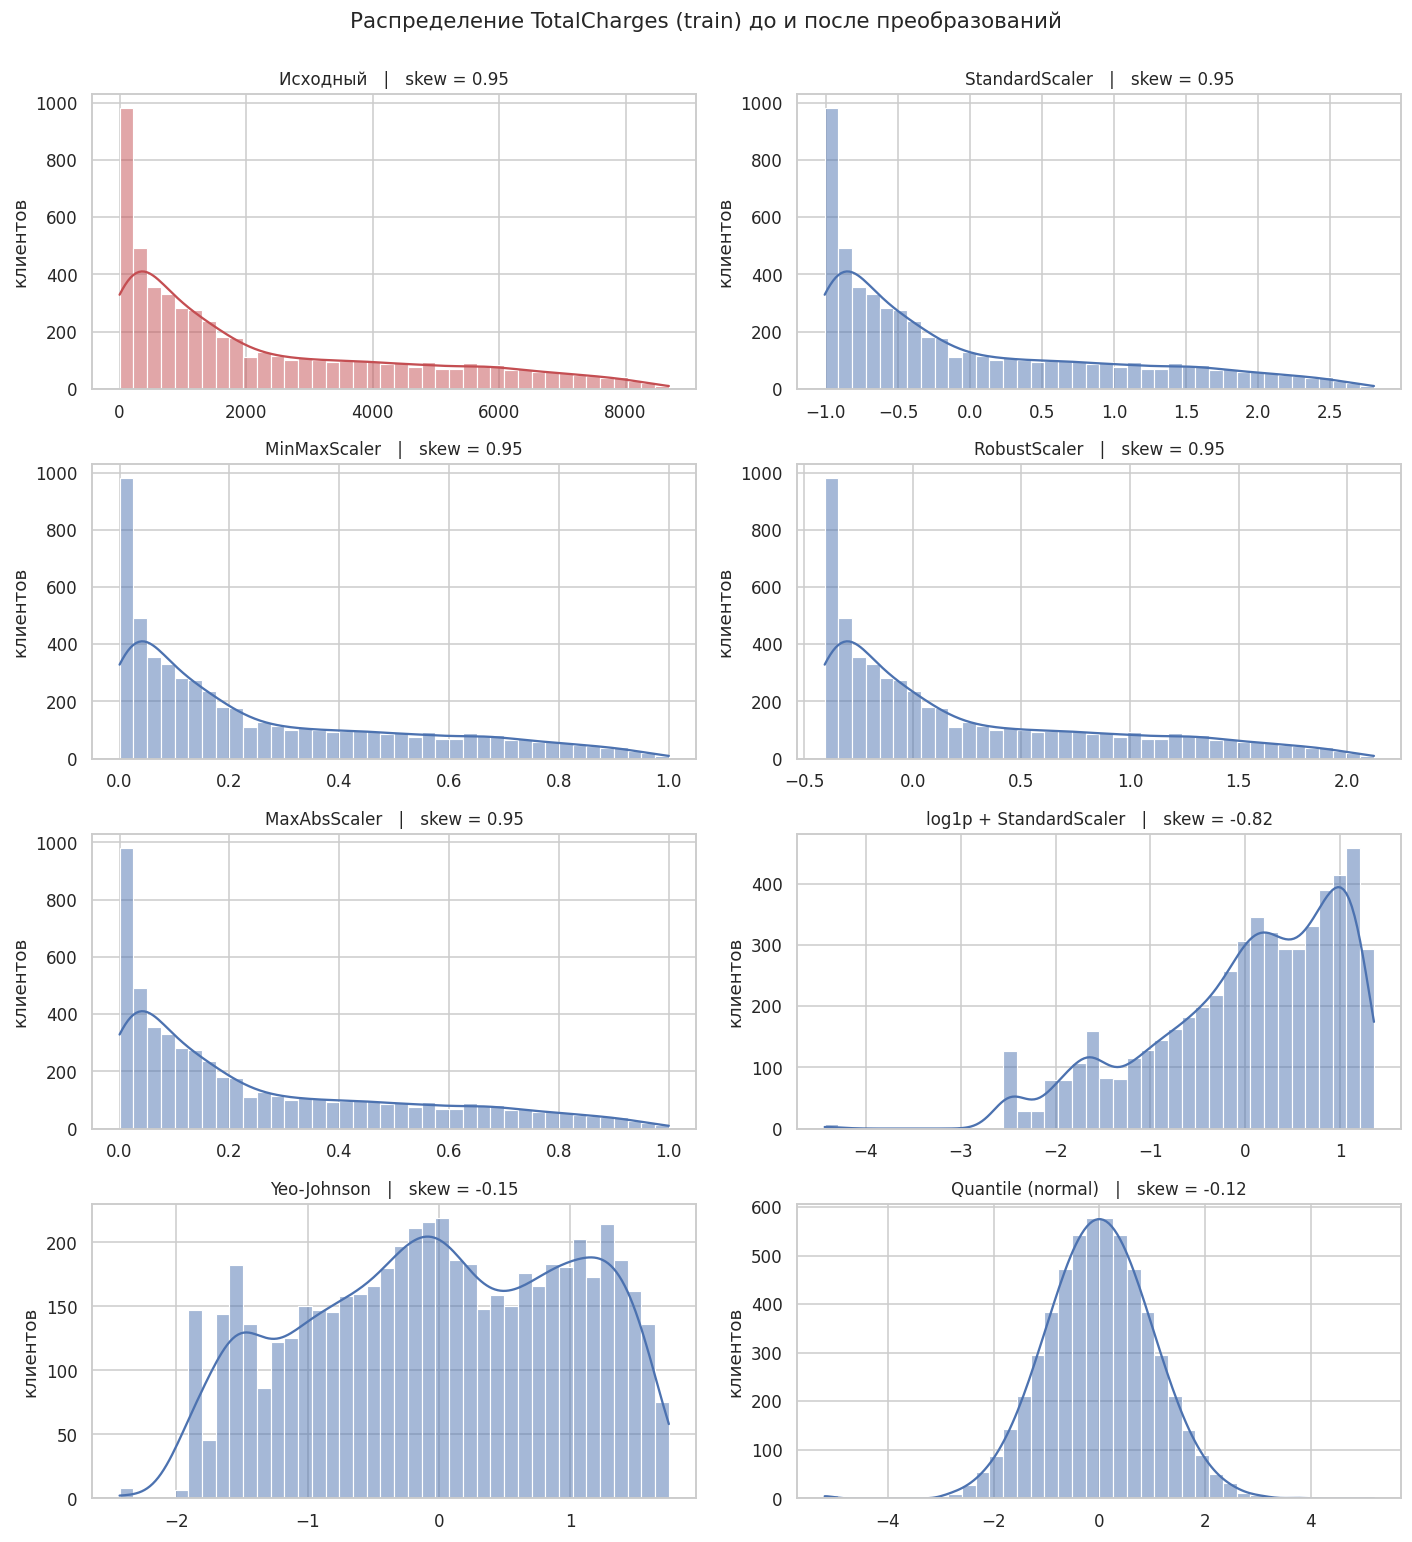

In [5]:
names = list(train_tf.keys())
fig, axes = plt.subplots(4, 2, figsize=(13, 14))
for ax, name in zip(axes.ravel(), names):
    a = train_tf[name]
    sns.histplot(a, bins=40, kde=True, color='#C44E52' if name == 'Исходный' else '#4C72B0', ax=ax)
    ax.set_title(f'{name}   |   skew = {stats.skew(a):.2f}')
    ax.set_xlabel(''); ax.set_ylabel('клиентов')
plt.suptitle(f'Распределение {FEATURE} (train) до и после преобразований', y=1.0, fontsize=14)
plt.tight_layout(); plt.show()

**Q–Q графики** показывают, насколько распределение близко к нормальному: чем ближе точки к красной прямой, тем ближе к нормальному.
Показываем исходный признак и три принципиально разных варианта.

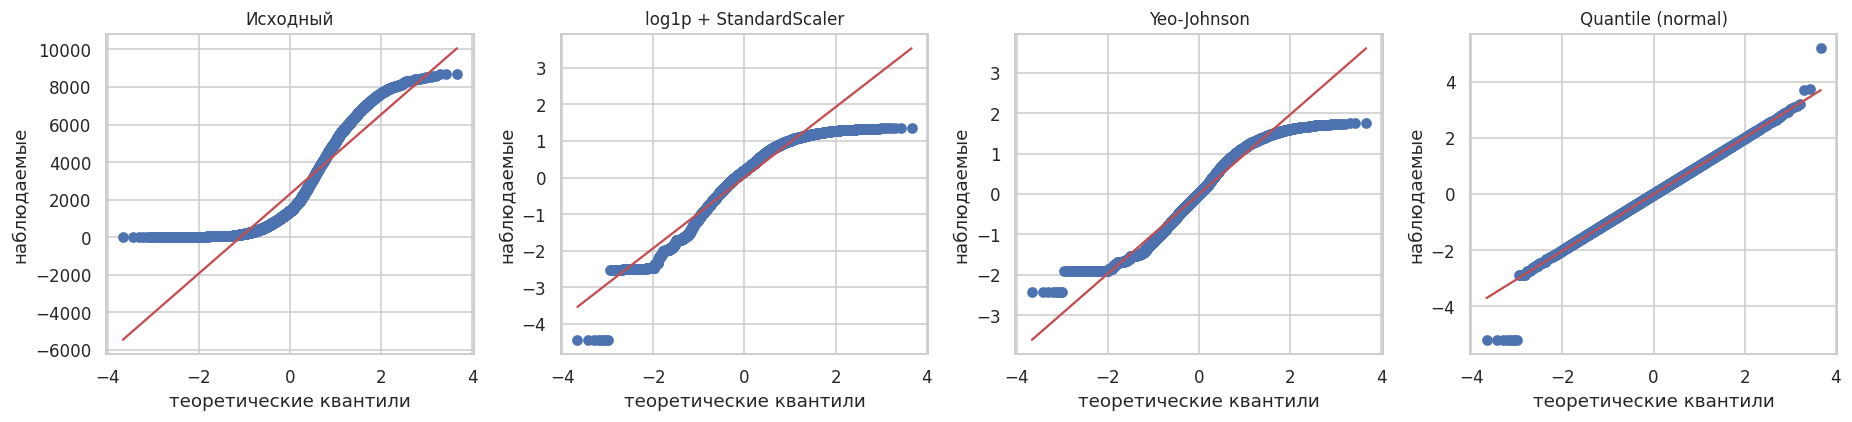

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, name in zip(axes, ['Исходный', 'log1p + StandardScaler', 'Yeo-Johnson', 'Quantile (normal)']):
    stats.probplot(train_tf[name], dist='norm', plot=ax)
    ax.set_title(name); ax.set_xlabel('теоретические квантили'); ax.set_ylabel('наблюдаемые')
plt.tight_layout(); plt.show()

## 3. Сравнение методов и выбор

Для объективного сравнения посчитаем числовые характеристики после каждого преобразования:

* **среднее, std, min, max** — как изменился масштаб;
* **skew и эксцесс** — насколько форма близка к нормальной (идеал: 0 и 0);
* **выбросы по IQR, %** — доля точек за границами 1.5·IQR;
* **корреляция Пирсона с исходным признаком** — сохраняет ли преобразование линейные соотношения (1.0 — форма не менялась, меньше — форма деформирована).

In [7]:
def characterize(a, orig):
    q1, q3 = np.percentile(a, [25, 75])
    iqr = q3 - q1
    return {
        'среднее': a.mean(), 'std': a.std(), 'min': a.min(), 'max': a.max(),
        'skew': stats.skew(a), 'эксцесс': stats.kurtosis(a),
        'выбросы IQR, %': ((a < q1 - 1.5 * iqr) | (a > q3 + 1.5 * iqr)).mean() * 100,
        'корр. с исходным': np.corrcoef(a, orig)[0, 1],
    }

comp = pd.DataFrame({n: characterize(a, orig_train) for n, a in train_tf.items()}).T
comp.round(3)

,среднее,std,min,max,skew,эксцесс,"выбросы IQR, %",корр. с исходным
Исходный,2299.335,2279.002,0.000,8684.800,0.949,-0.265,0.000,1.000
StandardScaler,0.000,1.000,-1.009,2.802,0.949,-0.265,0.000,1.000
MinMaxScaler,0.265,0.262,0.000,1.000,0.949,-0.265,0.000,1.000
RobustScaler,0.263,0.664,-0.406,2.124,0.949,-0.265,0.000,1.000
MaxAbsScaler,0.265,0.262,0.000,1.000,0.949,-0.265,0.000,1.000
log1p + StandardScaler,-0.000,1.000,-4.435,1.358,-0.819,0.078,0.142,0.827
Yeo-Johnson,0.000,1.000,-2.433,1.752,-0.147,-1.036,0.000,0.920
Quantile (normal),-0.002,1.013,-5.199,5.199,-0.116,0.777,0.657,0.920


In [8]:
# контроль отсутствия утечки: статистики test после преобразования, обученного на train
comp_test = pd.DataFrame({n: characterize(a, test_tf['Исходный']) for n, a in test_tf.items()}).T
md('**Те же характеристики на test** (преобразователи обучены на train — среднее и std на test не обязаны быть ровно 0 и 1):')
display(comp_test[['среднее', 'std', 'min', 'max', 'skew']].round(3))

**Те же характеристики на test** (преобразователи обучены на train — среднее и std на test не обязаны быть ровно 0 и 1):

,среднее,std,min,max,skew
Исходный,2201.361,2214.755,0.000,8496.700,1.021
StandardScaler,-0.043,0.972,-1.009,2.719,1.021
MinMaxScaler,0.253,0.255,0.000,0.978,1.021
RobustScaler,0.235,0.645,-0.406,2.069,1.021
MaxAbsScaler,0.253,0.255,0.000,0.978,1.021
log1p + StandardScaler,-0.036,1.011,-4.435,1.344,-0.842
Yeo-Johnson,-0.037,0.995,-2.433,1.726,-0.138
Quantile (normal),-0.044,1.009,-5.199,2.975,-0.249


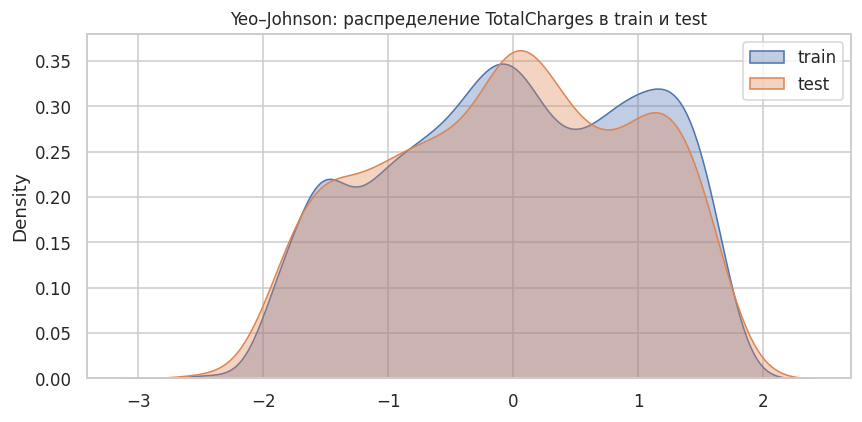

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(train_tf['Yeo-Johnson'], label='train', fill=True, alpha=.35, ax=ax)
sns.kdeplot(test_tf['Yeo-Johnson'], label='test', fill=True, alpha=.35, ax=ax)
ax.set_title('Yeo–Johnson: распределение TotalCharges в train и test'); ax.legend()
plt.tight_layout(); plt.show()

### Выводы о различиях между методами

**1. Линейные методы (Standard, MinMax, Robust, MaxAbs) не меняют форму распределения.** Корреляция с исходным признаком равна 1,00, а асимметрия остаётся исходной (skew ≈ 0,95): правый хвост никуда не делся,
меняются лишь центр и масштаб. Standard даёт среднее 0 и std 1; MinMax и MaxAbs дают значения в [0, 1] и здесь **совпадают**, потому что минимум признака равен 0; Robust центрирует по медиане.
Выбросов по IQR у `TotalCharges` нет, поэтому главное преимущество `RobustScaler` (устойчивость к выбросам) здесь не проявляется.

**2. `log1p + StandardScaler` перекорректирует.** Логарифм сильно растягивает малые значения и сжимает большие: асимметрия не исчезает, а **меняет знак** (skew ≈ −0,82), хвост теперь слева.
Это самая сильная деформация среди нелинейных методов (корреляция с исходным только 0,83), а клиенты с `TotalCharges = 0` оказываются далеко от остальных (≈ −4,4) и формально становятся выбросами.

**3. `Yeo–Johnson`: асимметрия практически убрана, выбросы не появляются.** Параметр λ ≈ 0,26 подобран по данным (между корнем и логарифмом), поэтому нет ни недо-, ни перекоррекции: skew снижается с 0,95 до ≈ −0,15.
Метод принимает нули (Box–Cox требует строго положительных значений), **гладкий и обратимый**, выбросов по IQR после него нет, а на test асимметрия почти такая же (−0,14), то есть преобразование устойчиво переносится на новые данные.
Честное ограничение: колоколообразной формы он не даёт — гистограмма «плосковершинная» (эксцесс ≈ −1,0), а Q–Q график S-образный с полками в нижней части. Причина в самом признаке:
у многих клиентов суммы малы (новички), и ни одна гладкая степенная функция не «растянет» эту плотную нижнюю область.

**4. `QuantileTransformer` даёт самую «нормальную» форму, но с побочными эффектами.** Q–Q график почти идеально ложится на прямую, skew ≈ −0,12. Однако метод опирается только на **ранги**:
(а) все нулевые значения отправляются в крайнюю точку ≈ −5,2, и появляются искусственные выбросы (≈ 0,7 % значений за границами 1.5·IQR, тогда как в исходном признаке их нет);
(б) исчезает информация о величине разрывов между значениями — одинаково «далеки» и близкие, и сильно различающиеся суммы, если между ними одинаковое число клиентов;
(в) на новых данных он менее устойчив: skew на test ≈ −0,25 против −0,12 на train (у Yeo–Johnson −0,14 против −0,15); обратное преобразование приближённое.

**Итог: для `TotalCharges` наиболее подходит `Yeo–Johnson` (`PowerTransformer`).** Он устраняет асимметрию, не создаёт выбросов, корректно обрабатывает нули, является гладкой обратимой функцией с одним параметром и устойчив при переносе с train на test.
`QuantileTransformer` стоит выбирать, только если модели действительно нужна строго гауссова форма и допустимы искусственные хвосты. Линейные методы масштабируют, но проблему скошенности не решают.
Влияние выбора на качество модели проверено отдельно в разделе 4.4: оно **небольшое**, поэтому выбор опирается прежде всего на свойства распределения.

*Оговорка:* масштабирование нужно моделям, чувствительным к масштабу и форме признаков (логистическая регрессия, SVM, KNN, нейросети). Деревьям и ансамблям на деревьях (Random Forest, градиентный бустинг) оно не нужно — они инвариантны к монотонным преобразованиям.

## 4. Предобработка всех оставшихся столбцов

Все преобразования ниже обучаются **только на `X_train`** и применяются к `X_test`.

### 4.1 План: что делаем с каждым столбцом и почему

| Столбцы | Тип | Метод | Обоснование |
|---|---|---|---|
| `customerID` | идентификатор | **удалить** | уникален у каждого клиента, предсказательной информации не несёт; модель могла бы его «запомнить» (переобучение) |
| `Churn` | целевая | `Yes/No → 1/0` | модели требуют числовую цель; 1 — «ушёл» |
| `MultipleLines`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` | «почти бинарные» (3 значения) | **`No internet service` / `No phone service` → `No`**, затем бинарное кодирование | эти значения дублируют информацию из `InternetService` и `PhoneService`; оставив их, мы получили бы лишние сильно коррелирующие столбцы |
| `gender`, `Partner`, `Dependents`, `PhoneService`, `PaperlessBilling` и сервисные столбцы из строки выше | бинарные | **`OneHotEncoder(drop='if_binary')`** → один столбец 0/1 | у двух категорий нет порядка; один столбец достаточно, второй был бы его зеркальным отражением |
| `SeniorCitizen` | уже бинарный 0/1 | без изменений (`passthrough`) | уже в нужном виде |
| `InternetService`, `PaymentMethod` | номинальные (3–4 значения, без порядка) | **`OneHotEncoder(drop='first')`** | порядок между значениями искусственен — обычное числовое кодирование (0, 1, 2) навязало бы модели несуществующую близость; `drop='first'` убирает линейную зависимость между дамми-столбцами |
| `Contract` | порядковый (Month-to-month < One year < Two year) | **`OrdinalEncoder`** с заданным порядком → 0, 1, 2 | у категорий есть естественный порядок по сроку обязательства; один столбец вместо двух дамми, и модель видит монотонность (чем длиннее контракт, тем меньше отток — это показал анализ в блокноте 1) |
| `tenure`, `MonthlyCharges` | числовые, без выраженной асимметрии (skew ≈ 0,2) и без выбросов | **`StandardScaler`** | форма уже близка к симметричной, степенное преобразование не нужно; Standard сохраняет форму и приводит масштаб к сопоставимому с остальными признаками |
| `TotalCharges` | числовой, скошенный | **`PowerTransformer` (Yeo–Johnson)** | выбран в разделе 3 |

Замена `No internet service → No` и `No phone service → No` — это **детерминированная замена значений** (не зависит от данных), поэтому утечки данных нет, и её можно применять к train и test одинаково.

In [10]:
SERVICE_COLS = ['MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                'TechSupport', 'StreamingTV', 'StreamingMovies']


def semantic_cleanup(X):
    """Детерминированные шаги (без обучения на данных): удаление ID и схлопывание избыточных категорий."""
    X = X.copy()
    X = X.drop(columns=['customerID'])
    X[SERVICE_COLS] = X[SERVICE_COLS].replace({'No internet service': 'No', 'No phone service': 'No'})
    return X


Xtr = semantic_cleanup(X_train)
Xte = semantic_cleanup(X_test)

print('Столбцов до / после:', X_train.shape[1], '/', Xtr.shape[1])
print('Уникальные значения сервисных столбцов после замены:',
      sorted(set(Xtr[SERVICE_COLS].stack().unique())))
Xtr.head()

Столбцов до / после: 20 / 19
Уникальные значения сервисных столбцов после замены: ['No', 'Yes']


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
3738,Male,0,No,No,35,No,No,DSL,No,No,Yes,No,Yes,Yes,Month-to-month,No,Electronic check,49.20,1701.65
3151,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,75.10,1151.55
4860,Male,0,Yes,Yes,13,No,No,DSL,Yes,Yes,No,Yes,No,No,Two year,No,Mailed check,40.55,590.35
3867,Female,0,Yes,No,26,Yes,No,DSL,No,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),73.50,1905.70
3810,Male,0,Yes,Yes,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Electronic check,44.55,44.55


In [11]:
binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling'] + SERVICE_COLS
passthrough_cols = ['SeniorCitizen']
nominal_cols = ['InternetService', 'PaymentMethod']
ordinal_cols = ['Contract']
numeric_std = ['tenure', 'MonthlyCharges']
numeric_pt = ['TotalCharges']

all_planned = binary_cols + passthrough_cols + nominal_cols + ordinal_cols + numeric_std + numeric_pt
assert sorted(all_planned) == sorted(Xtr.columns), 'не все столбцы учтены!'
print('Все', len(all_planned), 'столбцов распределены по группам.')

preprocessor = ColumnTransformer(
    transformers=[
        ('binary', OneHotEncoder(drop='if_binary', sparse_output=False), binary_cols),
        ('nominal', OneHotEncoder(drop='first', sparse_output=False), nominal_cols),
        ('ordinal', OrdinalEncoder(categories=[['Month-to-month', 'One year', 'Two year']]), ordinal_cols),
        ('num_std', StandardScaler(), numeric_std),
        ('num_power', PowerTransformer(method='yeo-johnson', standardize=True), numeric_pt),
        ('passthrough', 'passthrough', passthrough_cols),
    ],
    verbose_feature_names_out=False,
)
preprocessor.set_output(transform='pandas')

X_train_prep = preprocessor.fit_transform(Xtr)   # fit — только на train
X_test_prep = preprocessor.transform(Xte)        # test только преобразуется

print('train:', X_train_prep.shape, '| test:', X_test_prep.shape)
X_train_prep.head()

Все 19 столбцов распределены по группам.
train: (5634, 22) | test: (1409, 22)


,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,PaperlessBilling_Yes,MultipleLines_Yes,OnlineSecurity_Yes,OnlineBackup_Yes,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,InternetService_Fiber optic,InternetService_No,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Contract,tenure,MonthlyCharges,TotalCharges,SeniorCitizen
3738,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.102371,-0.521976,0.163483,0
3151,1.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,-0.711743,0.337478,-0.127790,0
4860,1.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,-0.793155,-0.809013,-0.562790,0
3867,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,2.0,-0.263980,0.284384,0.253602,0
3810,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,-1.281624,-0.676279,-1.683445,0


### 4.2 Проверка результата

In [12]:
checks = pd.DataFrame({
    'train': {'пропусков': int(X_train_prep.isna().sum().sum()),
              'нечисловых столбцов': int((~X_train_prep.dtypes.apply(pd.api.types.is_numeric_dtype)).sum()),
              'столбцов': X_train_prep.shape[1]},
    'test': {'пропусков': int(X_test_prep.isna().sum().sum()),
             'нечисловых столбцов': int((~X_test_prep.dtypes.apply(pd.api.types.is_numeric_dtype)).sum()),
             'столбцов': X_test_prep.shape[1]},
})
display(checks)
print('Столбцы одинаковы в train и test:', list(X_train_prep.columns) == list(X_test_prep.columns))
print('\nИтоговый список признаков:\n', list(X_train_prep.columns))

,train,test
пропусков,0,0
нечисловых столбцов,0,0
столбцов,22,22


Столбцы одинаковы в train и test: True

Итоговый список признаков:
 ['gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'PaperlessBilling_Yes', 'MultipleLines_Yes', 'OnlineSecurity_Yes', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'Contract', 'tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']


In [13]:
num_out = ['tenure', 'MonthlyCharges', 'TotalCharges']
md('**Числовые признаки после масштабирования** (параметры подобраны на train, поэтому у train среднее ≈ 0 и std ≈ 1, а у test значения близки, но не равны):')
display(pd.concat({'train': X_train_prep[num_out].agg(['mean', 'std', 'min', 'max']).T,
                   'test': X_test_prep[num_out].agg(['mean', 'std', 'min', 'max']).T}, axis=1).round(3))

std_scaler = preprocessor.named_transformers_['num_std']
pt = preprocessor.named_transformers_['num_power']
print('\nПараметры, запомненные на train:')
print('  StandardScaler: среднее', dict(zip(numeric_std, std_scaler.mean_.round(2))),
      '| std', dict(zip(numeric_std, std_scaler.scale_.round(2))))
print('  Yeo–Johnson: λ =', pt.lambdas_.round(3))
print('  Порядок Contract:', preprocessor.named_transformers_['ordinal'].categories_[0].tolist())

**Числовые признаки после масштабирования** (параметры подобраны на train, поэтому у train среднее ≈ 0 и std ≈ 1, а у test значения близки, но не равны):

train                      test                     
                mean  std    min    max   mean    std    min    max
tenure          -0.0  1.0 -1.322  1.608 -0.023  0.998 -1.322  1.608
MonthlyCharges  -0.0  1.0 -1.544  1.786 -0.028  0.992 -1.549  1.721
TotalCharges     0.0  1.0 -2.433  1.752 -0.037  0.995 -2.433  1.726


Параметры, запомненные на train:
  StandardScaler: среднее {'tenure': np.float64(32.49), 'MonthlyCharges': np.float64(64.93)} | std {'tenure': np.float64(24.57), 'MonthlyCharges': np.float64(30.14)}
  Yeo–Johnson: λ = [0.258]
  Порядок Contract: ['Month-to-month', 'One year', 'Two year']


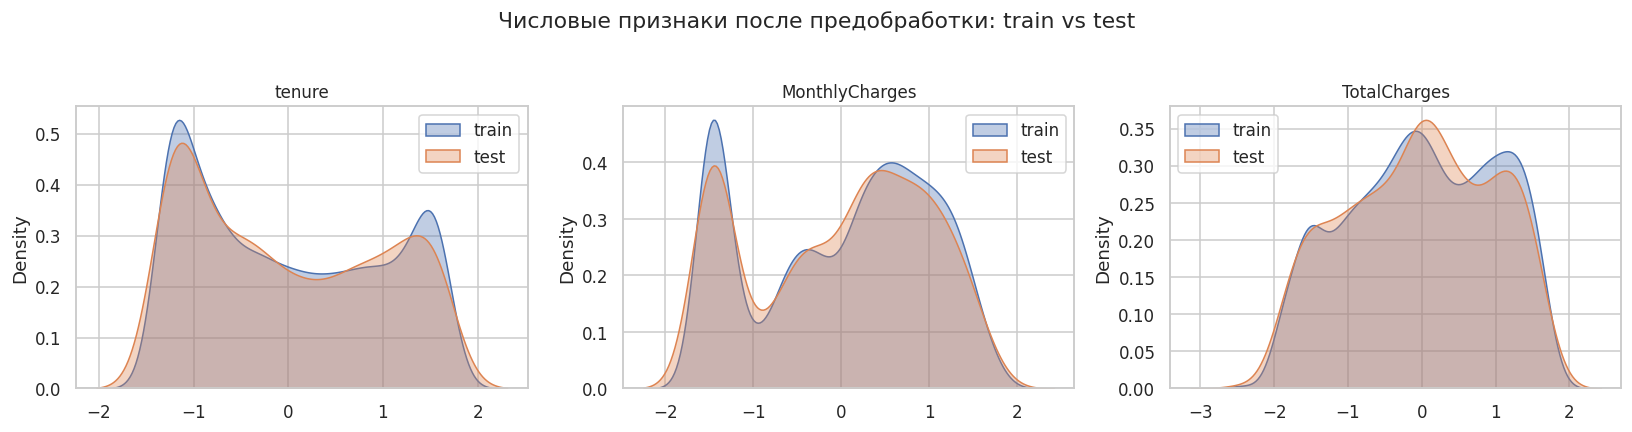

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, c in zip(axes, num_out):
    sns.kdeplot(X_train_prep[c], fill=True, alpha=.35, label='train', ax=ax)
    sns.kdeplot(X_test_prep[c], fill=True, alpha=.35, label='test', ax=ax)
    ax.set_title(c); ax.set_xlabel(''); ax.legend()
plt.suptitle('Числовые признаки после предобработки: train vs test', y=1.03)
plt.tight_layout(); plt.show()

### 4.3 Контрольный запуск: данные готовы к модели

Это не часть задания, а проверка, что на выходе — корректная числовая матрица: обучаем простую логистическую регрессию на `X_train_prep` и оцениваем на `X_test_prep`.

ROC-AUC (test):  0.846
Accuracy (test): 0.806  (для сравнения: доля класса «остался» = 0.735)


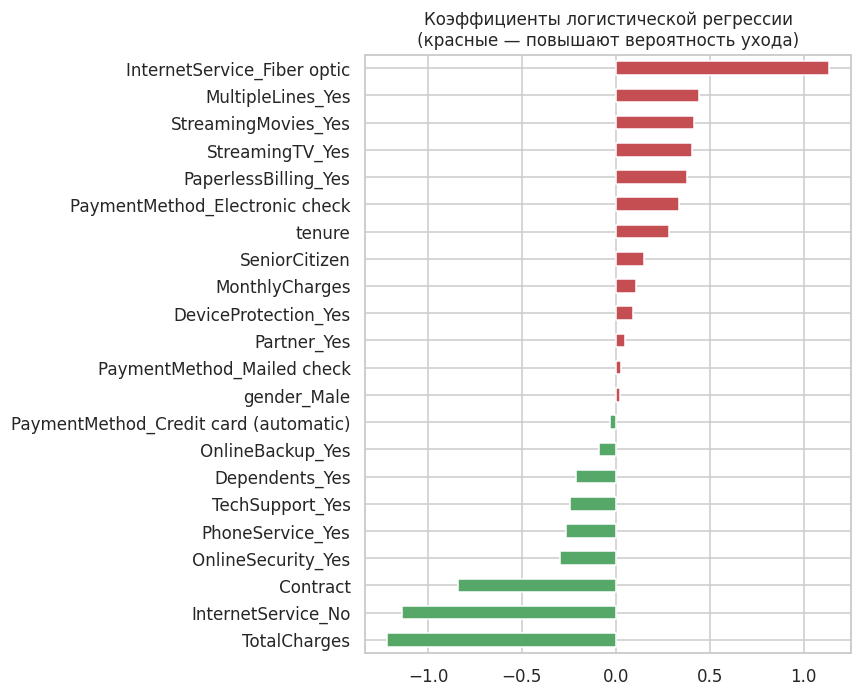

In [15]:
clf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
clf.fit(X_train_prep, y_train)
proba = clf.predict_proba(X_test_prep)[:, 1]

print(f'ROC-AUC (test):  {roc_auc_score(y_test, proba):.3f}')
print(f'Accuracy (test): {accuracy_score(y_test, clf.predict(X_test_prep)):.3f}  '
      f'(для сравнения: доля класса «остался» = {1 - y_test.mean():.3f})')

coef = pd.Series(clf.coef_[0], index=X_train_prep.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 6.5))
coef.plot.barh(color=np.where(coef > 0, '#C44E52', '#55A868'), ax=ax)
ax.set_title('Коэффициенты логистической регрессии\n(красные — повышают вероятность ухода)')
plt.tight_layout(); plt.show()

### 4.4 Влияет ли выбор метода для `TotalCharges` на качество модели?

Проверка чувствительности: оставляем все остальные признаки обработанными как выше, меняем только способ масштабирования `TotalCharges` и считаем **5-кратную стратифицированную кросс-валидацию ROC-AUC на train**
(преобразователь обучается внутри каждого фолда, test не используется). Берём две модели, чувствительные к масштабу: логистическую регрессию и KNN.

In [16]:
def make_pipeline(tc_transformer, model):
    ct = ColumnTransformer(
        transformers=[
            ('binary', OneHotEncoder(drop='if_binary', sparse_output=False), binary_cols),
            ('nominal', OneHotEncoder(drop='first', sparse_output=False), nominal_cols),
            ('ordinal', OrdinalEncoder(categories=[['Month-to-month', 'One year', 'Two year']]), ordinal_cols),
            ('num_std', StandardScaler(), numeric_std),
            ('num_tc', tc_transformer, numeric_pt),
            ('passthrough', 'passthrough', passthrough_cols),
        ])
    return Pipeline([('prep', ct), ('model', model)])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models = {'Логистическая регрессия': LogisticRegression(max_iter=2000),
          'KNN (k = 25)': KNeighborsClassifier(n_neighbors=25)}

rows = {}
for name, tc in transformers.items():
    rows[name] = {}
    for mname, model in models.items():
        sc = cross_val_score(make_pipeline(clone(tc), clone(model)), Xtr, y_train, cv=cv, scoring='roc_auc')
        rows[name][mname] = (sc.mean(), sc.std())

cv_table = pd.DataFrame({m: {n: f'{rows[n][m][0]:.4f} ± {rows[n][m][1]:.4f}' for n in rows} for m in models})
display(cv_table)

for m in models:
    means = pd.Series({n: rows[n][m][0] for n in rows})
    noise = np.mean([rows[n][m][1] for n in rows])
    md(f'* **{m}:** разброс между лучшим ({means.idxmax()}, {means.max():.4f}) и худшим ({means.idxmin()}, {means.min():.4f}) вариантами — '
       f'**{means.max() - means.min():.4f}**, при типичном стандартном отклонении между фолдами ≈ {noise:.4f}.')

,Логистическая регрессия,KNN (k = 25)
StandardScaler,0.8462 ± 0.0125,0.8347 ± 0.0085
MinMaxScaler,0.8460 ± 0.0124,0.8346 ± 0.0087
RobustScaler,0.8462 ± 0.0125,0.8356 ± 0.0084
MaxAbsScaler,0.8460 ± 0.0124,0.8346 ± 0.0087
log1p + StandardScaler,0.8499 ± 0.0114,0.8383 ± 0.0075
Yeo-Johnson,0.8498 ± 0.0111,0.8383 ± 0.0082
Quantile (normal),0.8480 ± 0.0105,0.8396 ± 0.0070


* **Логистическая регрессия:** разброс между лучшим (log1p + StandardScaler, 0.8499) и худшим (MinMaxScaler, 0.8460) вариантами — **0.0040**, при типичном стандартном отклонении между фолдами ≈ 0.0118.

* **KNN (k = 25):** разброс между лучшим (Quantile (normal), 0.8396) и худшим (MinMaxScaler, 0.8346) вариантами — **0.0050**, при типичном стандартном отклонении между фолдами ≈ 0.0081.

**Что видно.** Разница между методами в качестве модели мала и сопоставима с шумом между фолдами; линейные методы между собой практически неразличимы (для логистической регрессии они лишь меняют масштаб).
Нелинейные преобразования (`log1p`, `Yeo–Johnson`) дают небольшой прирост у логистической регрессии, но он не выходит за пределы случайных колебаний, поэтому утверждать «метод X улучшает качество» нельзя.
Следовательно, выбор `Yeo–Johnson` нужно обосновывать не метрикой, а свойствами распределения (раздел 3): он убирает асимметрию, не создаёт артефактов и устойчив на новых данных, не ухудшая при этом качества.

## 5. Итог

* **Разделение:** train/test = 80/20 со стратификацией; все преобразователи обучены только на train — утечки нет.
* **Масштабирование `TotalCharges`:** сравнили 7 методов. Линейные (Standard, MinMax, Robust, MaxAbs) лишь меняют масштаб, асимметрия остаётся ≈ 0,95; `log1p` перекорректирует (skew ≈ −0,82);
  `Quantile` даёт самую «нормальную» форму, но создаёт искусственные выбросы и менее устойчив на test; **`Yeo–Johnson`** снижает асимметрию до ≈ −0,15, корректно работает с нулями, обратим и устойчив — выбран как наиболее подходящий.
  Влияние выбора на качество модели невелико (раздел 4.4), поэтому решение опирается на свойства распределения.
* **Остальные столбцы:** `customerID` удалён; избыточные категории `No internet service` / `No phone service` схлопнуты в `No`; бинарные признаки закодированы одним столбцом 0/1; номинальные (`InternetService`, `PaymentMethod`) — one-hot;
  `Contract` — порядковое кодирование с заданным порядком; `tenure` и `MonthlyCharges` — `StandardScaler`; `SeniorCitizen` оставлен как есть.
* **Результат:** числовая матрица без пропусков и нечисловых столбцов, одинаковая структура в train и test; контрольная логистическая регрессия обучается и даёт осмысленные коэффициенты.

Ограничение: для моделей на деревьях масштабирование не обязательно, а дисбаланс классов (26,5 % ушедших) здесь не корректировался — это тема отдельного этапа моделирования.